In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score,confusion_matrix,classification_report,roc_auc_score,roc_curve

In [2]:
np.random.seed(42)
n=300
data=pd.DataFrame({
    "age":np.random.randint(18,60,n),
    "salary":np.random.randint(20000,100000,n),
    "balance":np.random.randint(0,200000,n)
})
data["churn"]=(
    (data["balance"]>100000).astype(int)|
    (data["salary"]<40000).astype(int)
).astype(int)
data.head()


,age,salary,balance,churn
0,56,59790,52528,0
1,46,25600,38413,1
2,32,60764,52638,0
3,25,94543,183808,1
4,38,65714,110133,1


In [5]:
print(data.shape)
print(data.info())
print(data.describe())
print(data['churn'].value_counts())


(300, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   age      300 non-null    int64
 1   salary   300 non-null    int64
 2   balance  300 non-null    int64
 3   churn    300 non-null    int64
dtypes: int64(4)
memory usage: 9.5 KB
None
              age        salary        balance       churn
count  300.000000    300.000000     300.000000  300.000000
mean    38.990000  59709.816667   96847.946667    0.646667
std     12.408187  22810.772819   55771.345393    0.478804
min     18.000000  20301.000000     404.000000    0.000000
25%     28.000000  40126.500000   50301.500000    0.000000
50%     40.000000  59189.500000  102245.500000    1.000000
75%     50.000000  79116.500000  141552.500000    1.000000
max     59.000000  99634.000000  199938.000000    1.000000
churn
1    194
0    106
Name: count, dtype: int64


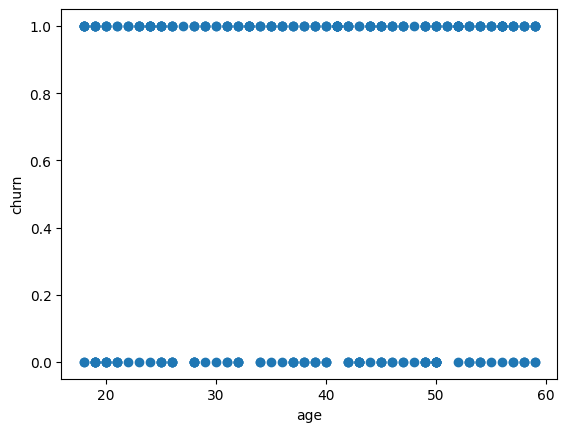

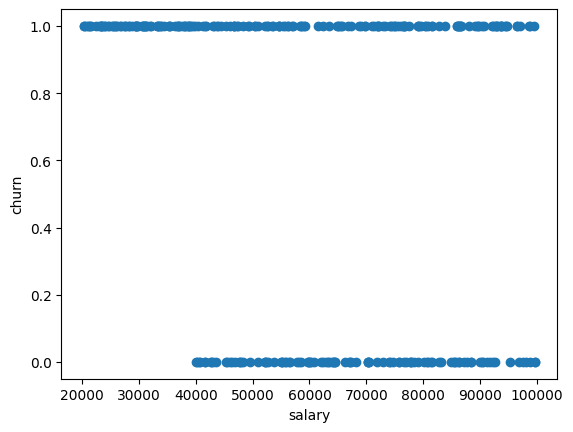

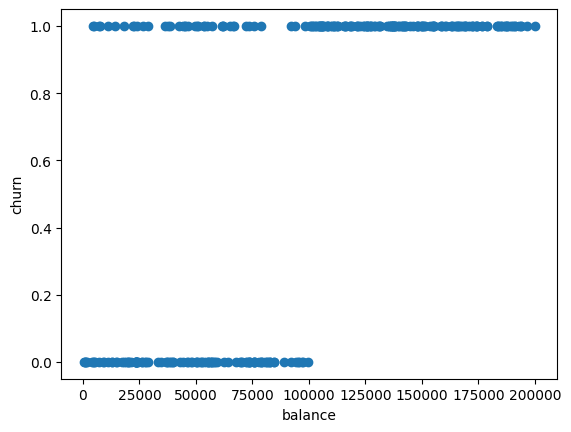

In [6]:
features= ["age","salary","balance"]
for col in features:
  plt.figure()
  plt.scatter(data[col], data["churn"])
  plt.xlabel(col)
  plt.ylabel("churn")
  plt.show()

In [8]:
x=data[["age","salary","balance"]]
y=data["churn"]

In [10]:
x_train , x_test ,y_train ,y_test =train_test_split(
    x,y,test_size=0.2, random_state=42
)

In [11]:
model=LogisticRegression(max_iter=1000)
model.fit(x_train,y_train)

LogisticRegression(max_iter=1000)

In [15]:
y_pred=model.predict(x_test)
y_prob=model.predict_proba(x_test)[:,1]
print(y_pred)
print(y_prob)

[1 1 1 1 1 1 0 1 1 1 1 1 1 1 1 1 1 0 1 1 1 0 1 0 0 1 1 1 0 1 1 1 1 1 1 1 1
 0 1 1 0 1 1 0 0 1 1 1 1 1 0 1 1 1 1 1 1 0 1 0]
[9.97844185e-01 9.88399418e-01 9.99043400e-01 9.96571108e-01
 7.50316484e-01 9.99742492e-01 4.45054161e-01 9.95788128e-01
 7.73404984e-01 9.99935507e-01 8.98871313e-01 9.42259805e-01
 9.97119820e-01 9.99615137e-01 9.93121302e-01 6.31341628e-01
 7.16297281e-01 1.97010991e-01 9.99575444e-01 7.86893221e-01
 8.55987350e-01 2.91707312e-04 9.53084288e-01 3.83840009e-03
 6.24725723e-02 9.08564225e-01 5.95703982e-01 9.96897029e-01
 4.67540319e-03 9.99720296e-01 6.08530477e-01 9.62703294e-01
 9.82277181e-01 9.97721329e-01 9.99928818e-01 9.92258644e-01
 9.84549899e-01 6.93247627e-02 9.95468456e-01 9.43167101e-01
 2.60085112e-01 8.39687125e-01 9.99827532e-01 8.08755842e-02
 2.71972063e-03 8.88335479e-01 9.99925753e-01 9.93564122e-01
 9.53029103e-01 9.12847859e-01 1.03722260e-01 5.18928840e-01
 7.50206245e-01 9.89380108e-01 9.98585112e-01 8.88090138e-01
 9.98382581e-01 3.14110

In [19]:
print("Accuracy:",accuracy_score(y_test,y_pred))
print("Confusion Matrix:\n",confusion_matrix(y_test,y_pred))
print("classification Report:\n",classification_report(y_test,y_pred))
print("ROC-AUC:",roc_auc_score(y_test,y_prob))

Accuracy: 0.8333333333333334
Confusion Matrix:
 [[10  7]
 [ 3 40]]
classification Report:
               precision    recall  f1-score   support

           0       0.77      0.59      0.67        17
           1       0.85      0.93      0.89        43

    accuracy                           0.83        60
   macro avg       0.81      0.76      0.78        60
weighted avg       0.83      0.83      0.83        60

ROC-AUC: 0.9165526675786594


In [21]:
coeff_df=pd.DataFrame({
    "feature":x.columns,
    "Coefficient":model.coef_[0]
})
print(coeff_df)

   feature  Coefficient
0      age     0.029959
1   salary    -0.000112
2  balance     0.000077


In [22]:
new_data=pd.DataFrame({
    "age":[35],
    "salary":[30000],
    "balance":[150000]
  })
print("churn Prediction:",model.predict(new_data)[0])
print("Probability:",model.predict_proba(new_data)[0][1])

churn Prediction: 1
Probability: 0.9999002730783279
